# 02 · LightGBM (gradient boosting, the M5 winner-style model)

**Owner:** Elena · **Reads:** notebook 01 outputs · **Feeds:** notebook 06 (hybrid model, ensemble) and 05 (scoring)

One LightGBM model learns from **all** California products at once (a "global" model), the way the top M5 solutions did.

**Two runs**
| Run | Model name in files | What the model sees |
|---|---|---|
| Sales only | `lgbm` | Past sales (lags and rolling averages), weekday/month, product/department/category/store |
| With covariates | `lgbm_cov` | Everything above + price, price vs. the previous 28 days, price change, SNAP days, events, Christmas (today's price and calendar are known in advance; comparisons use past prices only) |

**How it avoids peeking:** every sales feature is at least **28 days old**. For a window starting on day *S*, even the last day of the window only uses sales up to day *S − 1*. So one model forecasts all 28 days directly (no feeding forecasts back in), and it is trained only on days before *S*. A new model is trained for every window.

**Seven windows per run:** 4 backtests (`bt_4` … `bt_1`), `val_1`, `val_2`, `test`, identical to 02a/03/04a/04b. The backtests are what the hybrid model and ensemble learn from in 06.

**Output:** `data/forecasts/<model>_<window>.parquet` with columns `unique_id, ds, model, window, forecast`, so 05 scores them automatically.

**Runtime:** CPU is fine (LightGBM doesn't use the GPU here). Start with `SAMPLE = True` (100 products, about a minute). Then `SAMPLE = False` for all of California. If Colab disconnects, just run everything again: finished windows are skipped.

## Notes for Prateek (running locally)

**Status (Nov 19, 4 PM):** Elena ran this on free Colab (about 20 min per window).
- `lgbm` (sales only): **all 7 windows done**, files already in Drive `data/forecasts/`.
- `lgbm_cov` (with prices/holidays): **not finished**. This is what's left.

**To run the rest on your machine:**
1. In Settings, set `DRIVE_DIR = r"C:\path\to\your\local\AML_Term_Project"` (the folder that contains `data/`, like your TimesFM run). Make sure your local `data/` has `ca_sales.parquet`, `ca_static.parquet` and `windows.json`.
2. Set `RUNS = ["lgbm_cov"]`, keep `SAMPLE = False`, `OVERWRITE = False`.
3. Run all. LightGBM uses every CPU core automatically. Optional: `pip install lightgbm` first.
4. Upload the 7 `lgbm_cov_<window>.parquet` files to Drive `data/forecasts/` (if any `lgbm_cov` files from Elena's Colab run are already there, yours can replace them: same code and settings).
5. Section 7 saves `figures/12_lgbm_feature_importance.png` locally; upload it to Drive `data/figures/` too.

**Leak fix already included:** price features use past prices only (`price_ratio_28` = price / average price over the previous 28 days), per the team's note. 01's full-history `price_ratio` is not used.


## Local run copy (Prateek)
This is Elena's `02_lightgbm.ipynb` with **settings changes only** (the features and model are unchanged):
- `SAMPLE` comes from the `LGBM_SAMPLE` environment variable, set by `run_lgbm_test.bat` (100 products) and `run_lgbm_full.bat` (all of California)
- `RUNS = ["lgbm_cov"]`, because Elena already finished the sales-only `lgbm` run on Colab
- `DRIVE_DIR` is the folder this notebook sits in, which contains the same `data/` folder used for the TimesFM-3 run
- **GPU training:** `DEVICE` comes from `LGBM_DEVICE` (default `gpu`). LightGBM trains with its OpenCL GPU learner (`device_type="gpu"`); if the GPU can't be used, it switches to CPU automatically. GPU histograms use single precision, so forecasts can differ from a CPU run in the last decimals; the model and features are the same
- a file check at the end (section 8)

## Full California run of `lgbm_cov`: what was done (Nov 19, 2026)

> **Run notes added by Prateek.** Elena wrote this notebook and ran the sales-only model (`lgbm`, all 7 windows) and the first 2 windows of `lgbm_cov` on Colab. Prateek ran **all 7 `lgbm_cov` windows** on Nov 19. The notes in boxes like this one explain that run and its results. Elena's explanations and code are unchanged.

**Where it ran:** locally on a Windows laptop with an AMD Ryzen 7 5800H (8 cores, 16 threads), on the **CPU**. Elena's sales-only `lgbm` also ran on CPU, so the only difference between the two LightGBM runs is the covariates. (The local copy can also train on the GPU through LightGBM's OpenCL mode, but that wasn't used, for this reason.)

**Result:** all **7 forecast files** for all **12,196 California products**, finished in **27 minutes** (about 3.5 minutes per window, against about 20 on free Colab), with no errors.

**Environment:** a small conda environment (`lgbm`) with Python 3.11, LightGBM 4.7.0 and pandas 3.1.1.

**Elena's 2 Colab windows were replaced:** her `lgbm_cov_bt_3` and `lgbm_cov_bt_4` were overwritten in Drive by this run, so all 7 `lgbm_cov` files come from the same run and machine (same code and settings, as her notes allowed).

**Check before the full run:** the 100-product test (`run_lgbm_test.bat`) ran all 7 windows and matched an earlier test on a different machine to within 0.003 MAE (mean absolute error). The tiny difference is normal, because LightGBM's results shift slightly with the number of CPU threads.

## 0 · Settings

In [1]:
import os
# LOCAL RUN (Prateek): run_lgbm_test.bat sets LGBM_SAMPLE=1, run_lgbm_full.bat sets LGBM_SAMPLE=0. Opened by hand, it defaults to the test.
SAMPLE      = os.environ.get("LGBM_SAMPLE", "1") == "1"   # True = 100-product smoke test; False = all ~12,200 California series
RUNS        = ["lgbm_cov"]   # LOCAL RUN: only the with-covariates run (Elena finished "lgbm" on Colab)
N_BACKTEST  = 4          # extra 28-day windows before val_1 (same as 02a/04a/04b)
OVERWRITE   = False      # True = redo windows that already have a forecast file (only for the runs listed in RUNS)
DEVICE      = os.environ.get("LGBM_DEVICE", "gpu")   # LOCAL RUN: "gpu" (OpenCL, falls back to CPU if unavailable) or "cpu"
DRIVE_DIR   = os.path.abspath(".")   # LOCAL RUN: the folder this notebook sits in (it contains data/)

TRAIN_DAYS  = 730        # train on the last 2 years before each window
LAGS        = [28, 35, 42, 49, 56, 364]          # days back (all >= 28, so no peeking)
ROLL        = [7, 14, 28, 56, 112]               # rolling averages of the 28-day-old sales
COVARIATES  = ["sell_price", "price_ratio_28", "price_change_7", "price_vs_max",
               "snap", "is_event", "event_type", "is_christmas"]

N_ROUNDS    = 600
PARAMS = {
    "objective": "tweedie",          # suits counts with many zeros (standard in M5)
    "tweedie_variance_power": 1.1,
    "learning_rate": 0.05,
    "num_leaves": 127,
    "min_data_in_leaf": 100,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 0.1,
    "max_bin": 255,
    "seed": 42,
    "verbose": -1,
}
print("SAMPLE =", SAMPLE, "| RUNS =", RUNS, "| DEVICE =", DEVICE, "| DRIVE_DIR =", DRIVE_DIR)


SAMPLE = False | RUNS = ['lgbm_cov'] | DEVICE = cpu | DRIVE_DIR = C:\Users\bmpra\OneDrive\MSBA\Deep learning\Term Project\AML_Term_Project


> **Run note:** the printed line confirms the full run: `SAMPLE = False` (all products), `RUNS = ['lgbm_cov']`, `DEVICE = cpu`, and the local project folder as `DRIVE_DIR`. Elena's model settings (600 rounds, Tweedie loss, 127 leaves and the rest) are unchanged.

## 1 · Connect

In [2]:
import os, glob, json, time
import numpy as np
import pandas as pd
import lightgbm as lgb

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab: set DRIVE_DIR in Settings to your local AML_Term_Project folder.")

if DRIVE_DIR is None:
    DRIVE_DIR = os.environ.get("AML_DIR")
if DRIVE_DIR is None:
    found = (glob.glob("/content/drive/MyDrive/AML_Term_Project")
             or glob.glob("/content/drive/MyDrive/*/AML_Term_Project"))
    assert found, "Can't find AML_Term_Project in My Drive. Add the shortcut, or set DRIVE_DIR."
    DRIVE_DIR = found[0]
DATA_DIR = f"{DRIVE_DIR}/data"
OUT_DIR  = f"{DATA_DIR}/forecasts_sample" if SAMPLE else f"{DATA_DIR}/forecasts"
FIG_DIR  = f"{DATA_DIR}/figures"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
print("Reading", DATA_DIR, "| writing", OUT_DIR, "| LightGBM", lgb.__version__)
# LOCAL RUN: check the GPU once, before any real work. If LightGBM can't use it, switch to CPU.
if DEVICE == "gpu":
    try:
        _X = np.random.rand(2000, 5); _y = np.random.rand(2000)
        lgb.train({"objective": "tweedie", "device_type": "gpu", "verbose": -1}, lgb.Dataset(_X, _y), num_boost_round=2)
        print("GPU check passed: LightGBM will train on the GPU (OpenCL)")
    except Exception as e:
        print("GPU check failed:", str(e).splitlines()[0], "-> using CPU instead")
        DEVICE = "cpu"


Not running in Colab: set DRIVE_DIR in Settings to your local AML_Term_Project folder.
Reading C:\Users\bmpra\OneDrive\MSBA\Deep learning\Term Project\AML_Term_Project/data | writing C:\Users\bmpra\OneDrive\MSBA\Deep learning\Term Project\AML_Term_Project/data/forecasts | LightGBM 4.7.0


## 2 · Load data and windows

In [3]:
with open(f"{DATA_DIR}/windows.json") as f:
    wjson = json.load(f)
H = wjson["horizon"]

# Shared window list (identical to 02a/04a/04b): 4 backtests right before val_1, then val_1, val_2, test.
val1_start = pd.Timestamp(wjson["val_1"]["start"])
windows = {}
for k in range(N_BACKTEST, 0, -1):
    start = val1_start - pd.Timedelta(days=H * k)
    windows[f"bt_{k}"] = (start, start + pd.Timedelta(days=H - 1))
for name in ["val_1", "val_2", "test"]:
    windows[name] = (pd.Timestamp(wjson[name]["start"]), pd.Timestamp(wjson[name]["end"]))

# Only load the dates we need: training for the earliest window, plus the longest look-back
first_needed = min(s for s, _ in windows.values()) - pd.Timedelta(days=TRAIN_DAYS + max(LAGS) + max(ROLL) + 28)
cols = ["unique_id", "ds", "y", "sell_price", "snap", "is_event", "event_type", "is_christmas"]
df = pd.read_parquet(f"{DATA_DIR}/{'ca_sample100' if SAMPLE else 'ca_sales'}.parquet", columns=cols)
df["ds"] = pd.to_datetime(df["ds"])
df = df[df["ds"] >= first_needed]
df["unique_id"] = df["unique_id"].astype(str)
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

static = pd.read_parquet(f"{DATA_DIR}/ca_static.parquet")
static["unique_id"] = static["unique_id"].astype(str)
df = df.merge(static[["unique_id", "item_id", "dept_id", "cat_id", "store_id"]], on="unique_id", how="left")

# Rows must be one per product per day with no gaps, so "shift by 28 rows" = "28 days ago"
step = df.groupby("unique_id", sort=False)["ds"].diff().dropna()
assert (step == pd.Timedelta(days=1)).all(), "Gaps in the daily data: lags would be wrong"

print(f"{df['unique_id'].nunique():,} series, {len(df):,} rows, {df['ds'].min().date()} → {df['ds'].max().date()}")
pd.DataFrame({w: {"start": s.date(), "end": e.date()} for w, (s, e) in windows.items()}).T

12,196 series, 15,220,951 rows, 2012-06-23 → 2016-05-22


,start,end
bt_4,2015-11-09,2015-12-06
bt_3,2015-12-07,2016-01-03
bt_2,2016-01-04,2016-01-31
bt_1,2016-02-01,2016-02-28
val_1,2016-02-29,2016-03-27
val_2,2016-03-28,2016-04-24
test,2016-04-25,2016-05-22


> **Run note:** 12,196 products and 15.2 million rows. That's fewer rows than the full 18.6 million in `ca_sales.parquet`, because the notebook only loads the dates it needs (from 2012-06-23: the earliest window's 2 training years plus the longest look-back). The 7 windows are the same as every other model's.

## 3 · Features
Built once for all dates. Every sales feature looks at least 28 days back, so for any day in a window it only uses sales from before the window started.

| Feature | Meaning |
|---|---|
| `lag_28` … `lag_364` | Sales exactly that many days earlier (`lag_364` = same weekday last year) |
| `rmean_7` … `rmean_112` | Average daily sales over the 7…112 days ending 28 days ago |
| `rstd_28`, `rzero_28` | Spread of sales, and share of zero-sales days, over those 28 days |
| `dow`, `dom`, `month` | Weekday, day of month, month |
| `item_id`, `dept_id`, `cat_id`, `store_id` | Which product and store (categories) |
| covariates (`lgbm_cov` only) | Price, price vs. its average over the previous 28 days, % change vs. last week, price vs. its highest so far, SNAP, events, Christmas. All price features use past prices only (01's `price_ratio` uses the full-history average, so it isn't used here) |

In [4]:
def rolling_by_product(x, ids, w):
    # Rolling mean, std and zero-share over the last w rows of each product, fully vectorised
    v = x.fillna(0).astype("float64")
    ok = x.notna().astype("float64")
    z = (x == 0).astype("float64")
    parts = {"s": v, "ss": v * v, "n": ok, "z": z}
    out = {}
    for k, s in parts.items():
        cs = s.groupby(ids, sort=False).cumsum()
        out[k] = cs - cs.groupby(ids, sort=False).shift(w).fillna(0)
    n = out["n"].replace(0, np.nan)
    mean = out["s"] / n
    var = (out["ss"] / n - mean ** 2) * n / (n - 1)
    return mean, np.sqrt(var.clip(lower=0)), out["z"] / n

t0 = time.time()
ids = df["unique_id"]
g = df.groupby("unique_id", sort=False)["y"]
for L in LAGS:
    df[f"lag_{L}"] = g.shift(L).astype("float32")

for w in ROLL:
    m, s, zr = rolling_by_product(df["lag_28"], ids, w)
    df[f"rmean_{w}"] = m.astype("float32")
    if w == 28:
        df["rstd_28"] = s.astype("float32")
        df["rzero_28"] = zr.astype("float32")

df["dow"] = df["ds"].dt.dayofweek.astype("int8")
df["dom"] = df["ds"].dt.day.astype("int8")
df["month"] = df["ds"].dt.month.astype("int8")

# Price features (prices are set in advance, so the window's own prices are allowed, same as chronos2_cov)
gp = df.groupby("unique_id", sort=False)["sell_price"]
df["price_change_7"] = (df["sell_price"] / gp.shift(7) - 1).astype("float32")
df["price_vs_max"] = (df["sell_price"] / gp.cummax()).astype("float32")
# Price vs. its average over the PREVIOUS 28 days. (01's price_ratio divides by the full-history
# average, which includes future prices, so we don't use it here.)
past_price_mean, _, _ = rolling_by_product(gp.shift(1), ids, 28)
df["price_ratio_28"] = (df["sell_price"] / past_price_mean).astype("float32")

for c in ["item_id", "dept_id", "cat_id", "store_id", "event_type"]:
    df[c] = df[c].astype(str).astype("category")

BASE_FEATS = ([f"lag_{L}" for L in LAGS] + [f"rmean_{w}" for w in ROLL] + ["rstd_28", "rzero_28"]
              + ["dow", "dom", "month", "item_id", "dept_id", "cat_id", "store_id"])
FEATURES = {"lgbm": BASE_FEATS, "lgbm_cov": BASE_FEATS + COVARIATES}
CATS = ["item_id", "dept_id", "cat_id", "store_id", "event_type"]
print(f"Features built in {time.time() - t0:.0f}s: {len(BASE_FEATS)} sales-only, {len(FEATURES['lgbm_cov'])} with covariates")

C:\Users\bmpra\AppData\Local\Temp\ipykernel_5220\4109070847.py:29: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["ds"].dt.dayofweek.astype("int8")


Features built in 61s: 20 sales-only, 28 with covariates


> **Run note:** features took 61 seconds on all products: 20 sales-only features plus 8 covariates (price, price compared with its last-28-day average, price change, price compared with its highest so far, SNAP, events, event type, Christmas) = 28 for `lgbm_cov`.

## 4 · Train and forecast one window
For a window starting on day *S*:
- **Training rows** = the `TRAIN_DAYS` days before *S* (actual sales of the window are never used)
- **Forecast rows** = the 28 window days, for every product with at least one day of history before *S* (same rule as the other notebooks)
- Forecasts below zero are set to zero

In [5]:
importances = {}

def train_model(make_dataset):
    # LOCAL RUN: train on the GPU if DEVICE == "gpu"; if that fails mid-run, switch to CPU for the rest
    global DEVICE
    if DEVICE == "gpu":
        try:
            return lgb.train({**PARAMS, "device_type": "gpu"}, make_dataset(), num_boost_round=N_ROUNDS)
        except lgb.basic.LightGBMError as e:
            print("  GPU training failed:", str(e).splitlines()[0], "-> switching to CPU")
            DEVICE = "cpu"
    return lgb.train(PARAMS, make_dataset(), num_boost_round=N_ROUNDS)

def forecast_window(run, wname, start, end):
    feats = FEATURES[run]
    cats = [c for c in CATS if c in feats]
    train = df[(df["ds"] < start) & (df["ds"] >= start - pd.Timedelta(days=TRAIN_DAYS)) & df["lag_28"].notna()]
    ids = df.loc[df["ds"] < start, "unique_id"].unique()
    pred = df[(df["ds"] >= start) & (df["ds"] <= end) & df["unique_id"].isin(ids)]

    model = train_model(lambda: lgb.Dataset(train[feats], label=train["y"], categorical_feature=cats, free_raw_data=True))
    importances[(run, wname)] = pd.Series(model.feature_importance("gain"), index=feats)

    res = pred[["unique_id", "ds"]].copy()
    res["forecast"] = np.clip(model.predict(pred[feats]), 0, None).astype("float32")
    res["model"] = run
    res["window"] = wname
    return res[["unique_id", "ds", "model", "window", "forecast"]].reset_index(drop=True), len(train)

## 5 · Run everything (skips windows already saved)

In [6]:
log_rows = []
for run in RUNS:
    for wname, (start, end) in windows.items():
        path = f"{OUT_DIR}/{run}_{wname}.parquet"
        if os.path.exists(path) and not OVERWRITE:
            print(f"skip  {run:8s} {wname:6s} (already saved)")
            continue
        t0 = time.time()
        res, n_train = forecast_window(run, wname, start, end)
        assert len(res) == res["unique_id"].nunique() * H, "every product should have exactly 28 days"
        res.to_parquet(path, index=False)
        secs = time.time() - t0
        n = res["unique_id"].nunique()
        print(f"done  {run:8s} {wname:6s} {n:6,} series  {n_train:11,} training rows  {secs:6.1f}s  {DEVICE}")
        log_rows.append({"model": run, "window": wname, "series": n, "train_rows": n_train,
                         "seconds": round(secs, 1), "device": DEVICE, "sample": SAMPLE,
                         "run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M")})

if log_rows:
    log_path = f"{OUT_DIR}/run_log.csv"
    new = pd.DataFrame(log_rows)
    new.to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
    display(new)

done  lgbm_cov bt_4   12,175 series    8,256,372 training rows   226.0s  cpu


done  lgbm_cov bt_3   12,177 series    8,316,326 training rows   224.1s  cpu


done  lgbm_cov bt_2   12,185 series    8,375,396 training rows   229.1s  cpu


done  lgbm_cov bt_1   12,190 series    8,433,036 training rows   224.1s  cpu


done  lgbm_cov val_1  12,196 series    8,486,869 training rows   227.0s  cpu


done  lgbm_cov val_2  12,196 series    8,536,091 training rows   202.4s  cpu


done  lgbm_cov test   12,196 series    8,578,413 training rows   185.6s  cpu


,model,window,series,train_rows,seconds,device,sample,run_at
0,lgbm_cov,bt_4,12175,8256372,226.0,cpu,False,2026-11-19 18:50
1,lgbm_cov,bt_3,12177,8316326,224.1,cpu,False,2026-11-19 18:54
2,lgbm_cov,bt_2,12185,8375396,229.1,cpu,False,2026-11-19 18:58
3,lgbm_cov,bt_1,12190,8433036,224.1,cpu,False,2026-11-19 19:01
4,lgbm_cov,val_1,12196,8486869,227.0,cpu,False,2026-11-19 19:05
5,lgbm_cov,val_2,12196,8536091,202.4,cpu,False,2026-11-19 19:09
6,lgbm_cov,test,12196,8578413,185.6,cpu,False,2026-11-19 19:12


> **Run note: what section 5 shows**
> * **Speed:** 3 to 4 minutes per window (186 to 229 seconds), 27 minutes in total.
> * **Training data:** each window's model learns from 8.3 to 8.6 million rows (2 years × about 12,000 products).
> * **Product counts:** 12,175 to 12,190 in the earliest backtests and 12,196 from val_1 on. Products that launch later have no history before the earliest windows, so they're skipped there, the same products every other model skips.

## 6 · Quick check
Not the official evaluation (that's notebook 05). Mean absolute error per window for both LightGBM runs, next to the 4-week-average baseline and Chronos-2 if their files are in the same folder, all scored on exactly the same products and days.

In [7]:
actual = df[["unique_id", "ds", "y"]]
compare = RUNS + ["smean4", "chronos2_zs"]
rows = []
for wname in windows:
    m = actual
    for name in compare:
        p = f"{OUT_DIR}/{name}_{wname}.parquet"
        if os.path.exists(p):
            f = pd.read_parquet(p, columns=["unique_id", "ds", "forecast"])
            f["unique_id"] = f["unique_id"].astype(str); f["ds"] = pd.to_datetime(f["ds"])
            m = m.merge(f.rename(columns={"forecast": name}), on=["unique_id", "ds"])
    row = {"window": wname, "series": m["unique_id"].nunique()}
    for name in compare:
        if name in m:
            row[f"MAE {name}"] = (m[name] - m["y"]).abs().mean()
    rows.append(row)

check = pd.DataFrame(rows).set_index("window")
for name in RUNS:
    if f"MAE {name}" in check and "MAE smean4" in check:
        check[f"{name} vs smean4"] = (1 - check[f"MAE {name}"] / check["MAE smean4"]).map("{:.0%}".format)
check.round(3)

,series,MAE lgbm_cov
window,,
bt_4,12175,1.021
bt_3,12177,0.988
bt_2,12185,1.035
bt_1,12190,1.062
val_1,12196,1.097
val_2,12196,1.076
test,12196,1.104


> **Run note: how to read the table above**
>
> Only the `lgbm_cov` column appears, because the other models' files weren't in the local folder. For comparison, here are the **official Nov 18 test-window scores** from notebook 05, next to this run:
>
> | Model | Test MAE | vs 4-week average |
> |---|---|---|
> | TimesFM-3 zero-shot | 1.016 | 13% better |
> | Chronos-2 zero-shot | 1.026 | 12% better |
> | DeepAR | 1.084 | 8% better |
> | **LightGBM + covariates (this run)** | **1.104** | **6% better** |
> | Naive, 4-week average (`smean4`) | 1.172 | (baseline) |
>
> **So on average daily error, LightGBM with covariates beats the baseline but is behind the foundation models and DeepAR.** Its error rises from the backtests (about 1.0) to val and test (about 1.1), the same pattern every model shows, because the later windows are harder to forecast. Official numbers come from the final 05 run.

## 7 · What the model relies on
Share of total gain per feature, averaged over the 7 windows (only windows trained in this session). Useful for the blog: it shows whether prices and holidays actually matter.

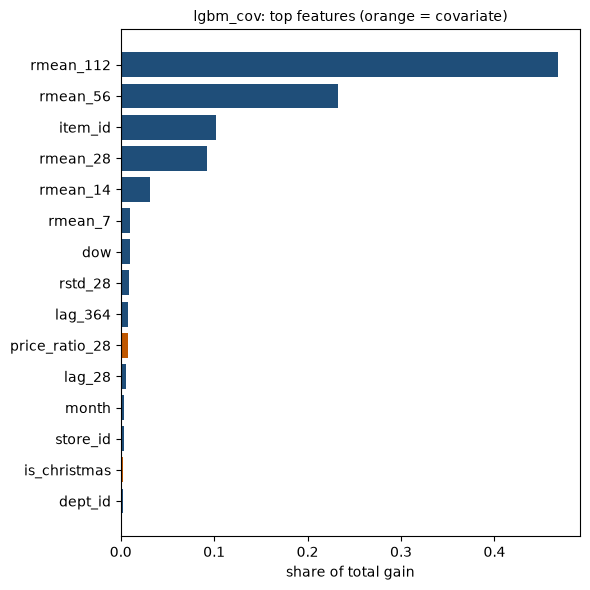

In [8]:
import matplotlib.pyplot as plt
if importances:
    fig, axes = plt.subplots(1, len(RUNS), figsize=(6 * len(RUNS), 6))
    for ax, run in zip(np.atleast_1d(axes), RUNS):
        imp = [s / s.sum() for (r, _), s in importances.items() if r == run]
        if not imp:
            ax.set_axis_off(); continue
        top = pd.concat(imp, axis=1).mean(axis=1).sort_values().tail(15)
        ax.barh(top.index, top.values, color=["#BF5700" if f in COVARIATES else "#1f4e79" for f in top.index])
        ax.set_title(f"{run}: top features (orange = covariate)", fontsize=10)
        ax.set_xlabel("share of total gain")
    plt.tight_layout()
    if not SAMPLE:
        plt.savefig(f"{FIG_DIR}/12_lgbm_feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Every window was already saved, so no models were trained this session (set OVERWRITE = True to retrain).")

> **Run note: what the chart shows** (also saved as `figures/12_lgbm_feature_importance.png`)
> * The model relies almost entirely on **recent sales averages**: the 112-day average (`rmean_112`, about 47% of the total gain) and the 56-day average (about 23%), followed by the product ID (`item_id`, about 10%) and the 28-day average (about 9%).
> * **Covariates barely matter.** The most useful price feature (`price_ratio_28`) has about 1% of the gain, and Christmas less than that. SNAP days and events don't reach the top 15.
> * This matches the foundation models, where covariates also changed the error by about 1% or less: **for this data, past sales carry almost all the signal.**

## 8 · Local check of the saved files
Expect 7 `lgbm_cov` files, every product with exactly 28 days, no missing and no negative forecasts.

In [9]:
rows = []
for p in sorted(glob.glob(f"{OUT_DIR}/lgbm_cov_*.parquet")):
    f = pd.read_parquet(p)
    rows.append({"file": os.path.basename(p), "series": f["unique_id"].nunique(), "rows": len(f),
                 "rows_ok": len(f) == f["unique_id"].nunique() * H, "missing": int(f["forecast"].isna().sum()),
                 "negative": int((f["forecast"] < 0).sum())})
summary = pd.DataFrame(rows)
print(len(summary), "lgbm_cov files found (expect 7)")
summary

7 lgbm_cov files found (expect 7)


,file,series,rows,rows_ok,missing,negative
0,lgbm_cov_bt_1.parquet,12190,341320,True,0,0
1,lgbm_cov_bt_2.parquet,12185,341180,True,0,0
2,lgbm_cov_bt_3.parquet,12177,340956,True,0,0
3,lgbm_cov_bt_4.parquet,12175,340900,True,0,0
4,lgbm_cov_test.parquet,12196,341488,True,0,0
5,lgbm_cov_val_1.parquet,12196,341488,True,0,0
6,lgbm_cov_val_2.parquet,12196,341488,True,0,0


> **Run note: file check results and extra checks**
>
> All 7 files are complete: every product has exactly 28 days (`rows_ok` True), with no missing and no negative forecasts.
>
> Extra checks on the **test window**, done after the run by comparing the file with actual sales in `ca_sales.parquet` and with TimesFM-3 zero-shot's file (all 341,488 rows matched):
>
> | Sales speed | MAE, LightGBM + cov | MAE, TimesFM-3 zero-shot | Units forecast ÷ units sold, LightGBM + cov | Units forecast ÷ units sold, TimesFM-3 |
> |---|---|---|---|---|
> | Slow | 0.434 | **0.331** | **84%** | 17% |
> | Medium | 0.843 | **0.788** | **90%** | 56% |
> | Fast | 2.035 | **1.928** | **95%** | 83% |
> | **All** | 1.104 | **1.016** | **93%** | 73% |
>
> **The most important finding of this run:** LightGBM is behind TimesFM-3 on daily error in every sales-speed group, but it is **far closer on total demand**. For slow sellers it forecasts **84% of the units actually sold, against 17% for TimesFM-3**, which predicts close to zero for them. Only 39% of LightGBM's forecasts are below 0.5 units, against 55% for TimesFM-3.
>
> This is the "best daily accuracy is not best for inventory" trade-off in its clearest form. Mean absolute error rewards forecasting zero for products that rarely sell; LightGBM's Tweedie loss (built for counts with many zeros) forecasts small realistic amounts instead. It suggests sending slow sellers to LightGBM in the ensemble (a routed ensemble by sales speed), and checking that idea with the bias, coverage and safety-stock numbers in notebook 05, not only MAE.

## Summary of the `lgbm_cov` run (Nov 19, 2026)

**Outputs**
* 7 forecast files `lgbm_cov_{bt_4 … test}.parquet` in Drive `AML_Term_Project/data/forecasts/` (not in GitHub, because data files are kept in Drive)
* `figures/12_lgbm_feature_importance.png`
* This executed notebook

**Main findings (quick check; official numbers come from notebook 05)**
1. Test MAE **1.104**: 6% better than the 4-week-average baseline, but behind TimesFM-3 (1.016), Chronos-2 (1.026) and DeepAR (1.084).
2. It forecasts **93% of total units sold** (TimesFM-3: 73%), and **84% for slow sellers** (TimesFM-3: 17%). It's the first model in the project that forecasts slow sellers' demand rather than near zero.
3. **Prices and holidays add almost nothing:** the top price feature has about 1% of the model's gain. Recent sales averages and the product ID do almost all the work.
4. On a laptop CPU (8 cores) the full run takes **27 minutes**, against about 20 minutes **per window** on free Colab.

**Next steps**
* Max's final 06 and 05 runs now have every LightGBM file.
* Worth testing in 06: route slow sellers to LightGBM and medium and fast sellers to TimesFM-3, judged on totals and safety stock as well as MAE.